# Step 5.0: Clean Baseline for the Perturbation Experiments

Inference only. The Step 4 checkpoints are reloaded and never modified.

Two things happen here.

**The integrity gate.** The checkpoints are reloaded, the architectures rebuilt from source, and the clean test RMSE reproduced. It must match what Step 4 wrote to within 0.01 K. Evaluation is deterministic in `eval()` mode, so a larger discrepancy is a fault — a drifted layer definition, a wrong scaler constant, a reordered test partition — and any of those would flow silently into every attack that follows. The attack notebooks load weights through the same path, so passing this gate is what licenses them.

**The baseline denominators.** Every attack reports a degradation, `D = metric_attacked - metric_clean`, subtracted within the same model and seed. That pairing matters twice over: it removes the clean architecture gap, and it removes the per-seed bias offset, which turns out to be six times noisier than RMSE.

Errors are reported on the nine fixed-width bins of Step 4b, unchanged, so degradations remain directly comparable with the clean baseline. The clean-baseline table of the paper (RMSE, MAE, bias, gross-failure rate, mean and seed-to-seed standard deviation) is printed in Section 5.0.4.

The grid sampling is carried through to the export so that the attack notebooks read it rather than each re-deriving it.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

# Step 4 evaluated at 256. Conv-Attn's attention kernel dispatches on tensor shape,
# so a different batch size shifts the result by a few thousandths of a Kelvin —
# harmless, but it would show up as a non-zero gate residual.
BATCH_SIZE = 256

GATE_TOL_K      = 0.01     # per-seed agreement with Step 4
CATASTROPHIC_K  = 300.0    # |dT| above this counts as a gross failure

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA
# ==========================================
import common
device = common.get_device()

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = common.read_json(os.path.join(DATA_DIR, 'catalog_meta.json'))['label_noise_floor_K']
GRID        = prep['grid']
GRID_N      = GRID['seq_length']

tensors_path = os.path.join(DATA_DIR, 'sdss_tensors.h5')
catalog_path = os.path.join(DATA_DIR, 'sdss_final_catalog.csv')
for p in (tensors_path, catalog_path):
    assert os.path.exists(p), f'missing input: {p}'

missing = [f'{m}_seed{s}_best.pth' for s in SEEDS for m in MODELS
           if not os.path.exists(os.path.join(CKPT_DIR, f'{m}_seed{s}_best.pth'))]
assert not missing, f'missing checkpoints: {missing}'

print(f'Device            : {device}')
print(f'  teff_range      : {TEFF_RANGE:.4f} K   <- normalised RMSE x this = Kelvin')
print(f'  label-noise floor: {NOISE_FLOOR:.1f} K')
print(f'  grid            : {GRID["wave_start"]:.0f}-{GRID["wave_end"]:.0f} A, '
      f'{GRID_N} points, {GRID["km_s_per_pixel"]:.2f} km/s per pixel')
print(f'  checkpoints     : {len(SEEDS) * len(MODELS)} found')

Device            : cpu
  teff_range      : 5498.9161 K   <- normalised RMSE x this = Kelvin
  label-noise floor: 47.9 K
  grid            : 3600-10300 A, 4096 points, 76.96 km/s per pixel
  checkpoints     : 10 found


## 5.0.1 Parameter-matched architectures

Imported from `models.py`, the single definition used for training in Step 4a. It must not be edited: the checkpoints were written against it, and a renamed layer breaks `load_state_dict` or, worse, loads partially. The parity check is an assertion so that a drifted definition halts the notebook rather than producing a plausible but wrong baseline.

In [2]:
from models import check_parameter_parity

check_parameter_parity();

Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)


## 5.0.2 Test partition

Rows are selected exactly as `SDSSDataset` did in Step 4a — test rows of the catalog, sorted, read from the master tensor file. Reading the data the same way is what gives the gate its meaning: a gate that read differently could not detect a misalignment introduced by the reading.

Errors are reported on the nine fixed-width bins of Step 4b, unchanged. Perturbed evaluations subtract the matching row of the resulting table, so keeping the binning identical is what makes a degradation comparable with the clean baseline.

No region of the input is masked off or treated specially. Random positions in Step 5 are drawn uniformly over the full grid: the models were trained on all 4096 pixels, and excluding some of them at evaluation time would measure a different input space from the one they learned. That some regions carry less temperature information than others is part of what the perturbation experiments measure, not an artefact to be filtered out beforehand.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_dev = torch.from_numpy(X_test).to(device)

# the nine fixed-width bins of Step 4b, unchanged
REG_EDGES = common.REGIME_EDGES_K
regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]

assert not np.isnan(X_test).any(), 'NaN in the test tensor'
assert regime.isna().sum() == 0, 'a test label falls outside the regime edges'

print(f'test spectra : {N_TEST:,}')
print(f'Teff range   : {y_true_k.min():.0f} - {y_true_k.max():.0f} K')
print(f'tensor       : {tuple(X_dev.shape)}, '
      f'{X_dev.element_size() * X_dev.nelement() / 1e6:.0f} MB on {device}')
print()
for reg in regime.categories:
    print(f'  {str(reg):14s} n = {int(np.sum(np.asarray(regime == reg))):,}')

test spectra : 18,898
Teff range   : 3500 - 8997 K
tensor       : (18898, 1, 4096), 310 MB on cpu

  (3500, 4000]   n = 1,255
  (4000, 4500]   n = 1,413
  (4500, 5000]   n = 2,511
  (5000, 5500]   n = 2,438
  (5500, 6000]   n = 5,474
  (6000, 6500]   n = 3,246
  (6500, 7000]   n = 1,230
  (7000, 8000]   n = 1,088
  (8000, 9000]   n = 243


## 5.0.3 Integrity gate

Ten forward passes. Predictions are kept, since the denominators of the next section are computed from them.

In [4]:
def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


clean_pred, gate_rows = {}, []

for seed in SEEDS:
    for m in MODELS:
        t0 = time.time()
        model = load_model(m, seed)
        pred_k = predict(model, X_dev)
        clean_pred[(m, seed)] = pred_k

        rmse_now = float(np.sqrt(np.mean((pred_k - y_true_k) ** 2)))
        with open(os.path.join(RESULTS_DIR, f'summary_{m}_seed{seed}.json')) as f:
            rmse_ref = float(json.load(f)['test_rmse_kelvin'])
        gate_rows.append({'model': m, 'seed': seed, 'rmse_now_K': rmse_now,
                          'rmse_step4_K': rmse_ref, 'delta_K': rmse_now - rmse_ref})

        del model
        if device.type == 'cuda':
            torch.cuda.empty_cache()
        print(f'  {m:10s} seed {seed}  RMSE {rmse_now:7.2f} K   ({time.time() - t0:.1f}s)')

gate = pd.DataFrame(gate_rows)
display(gate.round(5))

worst = float(gate['delta_K'].abs().max())
print(f'\nmax |delta| = {worst:.5f} K   (tolerance {GATE_TOL_K} K)')
assert worst < GATE_TOL_K, (
    'GATE FAILED — the reloaded checkpoints do not reproduce Step 4. Do not proceed; '
    'check the class definitions, the scaler constants and the test-row ordering.')
print('GATE PASSED — the checkpoints reproduce the Step 4 baseline.')

  Conv-Pool  seed 0  RMSE   81.58 K   (17.3s)
  Conv-Attn  seed 0  RMSE   81.57 K   (22.5s)
  Conv-Pool  seed 1  RMSE   80.54 K   (12.7s)
  Conv-Attn  seed 1  RMSE   81.70 K   (20.8s)
  Conv-Pool  seed 2  RMSE   80.60 K   (12.8s)
  Conv-Attn  seed 2  RMSE   81.54 K   (20.5s)
  Conv-Pool  seed 3  RMSE   81.43 K   (12.6s)
  Conv-Attn  seed 3  RMSE   81.07 K   (20.8s)
  Conv-Pool  seed 4  RMSE   81.21 K   (12.6s)
  Conv-Attn  seed 4  RMSE   82.74 K   (22.1s)


,model,seed,rmse_now_K,rmse_step4_K,delta_K
0,Conv-Pool,0,81.58250,81.58249,0.00000
1,Conv-Attn,0,81.57425,81.58013,-0.00588
2,Conv-Pool,1,80.54146,80.54145,0.00001
3,Conv-Attn,1,81.70127,81.70545,-0.00418
4,Conv-Pool,2,80.60311,80.60311,-0.00000
5,Conv-Attn,2,81.53854,81.54360,-0.00506
6,Conv-Pool,3,81.43217,81.43216,0.00000
7,Conv-Attn,3,81.06914,81.06739,0.00175
8,Conv-Pool,4,81.20574,81.20575,-0.00001
9,Conv-Attn,4,82.74138,82.74351,-0.00212



max |delta| = 0.00588 K   (tolerance 0.01 K)
GATE PASSED — the checkpoints reproduce the Step 4 baseline.


## 5.0.4 Baseline denominators

Five quantities per model, per seed, overall and per regime.

RMSE and MAE are the headline measures. **Signed bias** is added because some artefacts, reddening above all, are expected to push predictions systematically in one direction, and a symmetric error measure would hide exactly the effect that matters. **The 99th percentile of |ΔT|** and the **gross-failure rate** are added because RMSE is dominated by the body of the distribution while a perturbation typically breaks the tail first: an attack that moves the worst 1% without moving the bulk is invisible in RMSE and obvious here.

One caution the numbers themselves impose. Bias has a per-seed scatter of roughly 3 K against an RMSE scatter of 0.5 K, so *absolute* bias is not comparable across architectures with five seeds: the detectable difference in the aggregate bias would be around 8 K, and larger again within a single temperature regime, where fewer spectra enter each value. It is usable only as a within-seed difference, which is how `D` is defined. Absolute bias is never to be reported as an architecture comparison.

In [5]:
def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


rows = []
for (m, seed), pred_k in clean_pred.items():
    rows.append({'model': m, 'seed': seed, 'regime': 'all',
                 **metrics(pred_k, y_true_k)})
    for reg in regime.categories:
        sel = np.asarray(regime == reg)
        if sel.sum():
            rows.append({'model': m, 'seed': seed, 'regime': str(reg),
                         **metrics(pred_k[sel], y_true_k[sel])})

baseline = pd.DataFrame(rows).sort_values(['regime', 'model', 'seed'])
baseline.to_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'), index=False)

print('Overall, mean +/- sd over five seeds (the clean-baseline table of the paper):')
display(baseline.query("regime == 'all'")
        .groupby('model')[['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']]
        .agg(['mean', 'std']).round(3))

print('\nPer regime — RMSE and signed bias (K):')
per_reg = baseline.query("regime != 'all'")
tab = per_reg.pivot_table(index='regime', columns='model',
                          values=['rmse_K', 'bias_K'], aggfunc='mean')
tab.columns = [f'{v.replace("_K", "")}_{mod}' for v, mod in tab.columns]
tab.insert(0, 'n', per_reg.groupby('regime')['n'].first())
display(tab.reindex(REG_LABELS).round(2))

Overall, mean +/- sd over five seeds (the clean-baseline table of the paper):


rmse_K          mae_K        bias_K        p99_abs_K         \
             mean    std    mean    std   mean    std      mean    std   
model                                                                    
Conv-Attn  81.725  0.617  57.317  0.517 -4.148  3.529   272.042  5.183   
Conv-Pool  81.073  0.477  56.790  0.411 -4.343  3.176   270.286  3.840   

          gross_fail_frac       
                     mean  std  
model                           
Conv-Attn           0.007  0.0  
Conv-Pool           0.007  0.0


Per regime — RMSE and signed bias (K):


,n,bias_Conv-Attn,bias_Conv-Pool,rmse_Conv-Attn,rmse_Conv-Pool
regime,,,,,
"(3500, 4000]",1255,-10.11,-1.06,60.17,57.54
"(4000, 4500]",1413,-9.69,-1.79,71.42,70.14
"(4500, 5000]",2511,-3.02,3.85,65.78,63.21
"(5000, 5500]",2438,-1.21,-2.98,77.35,75.23
"(5500, 6000]",5474,1.65,-4.48,71.22,70.68
"(6000, 6500]",3246,-11.70,-15.06,88.67,90.00
"(6500, 7000]",1230,4.77,11.86,115.31,117.30
"(7000, 8000]",1088,-11.88,-13.48,116.83,116.77
"(8000, 9000]",243,-22.51,-29.29,135.55,125.45


In [6]:
# ---- the interpretive scale for every attack that follows --------------------
for m in MODELS:
    s = baseline.query("regime == 'all' and model == @m")
    r = s['rmse_K'].mean()
    print(f'{m:10s} RMSE {r:6.2f} +/- {s["rmse_K"].std():.2f} K   '
          f'= {r / NOISE_FLOOR:.2f} x label-noise floor   '
          f'model error {np.sqrt(max(r ** 2 - NOISE_FLOOR ** 2, 0)):.1f} K')
    print(f'{"":10s} bias {s["bias_K"].mean():+6.2f} +/- {s["bias_K"].std():.2f} K   '
          f'p99|dT| {s["p99_abs_K"].mean():6.1f} K   '
          f'gross failures {100 * s["gross_fail_frac"].mean():.2f}%')

gap = (baseline.query("regime == 'all' and model == 'Conv-Attn'")['rmse_K'].mean()
       - baseline.query("regime == 'all' and model == 'Conv-Pool'")['rmse_K'].mean())
sd_pool = baseline.query("regime == 'all' and model == 'Conv-Pool'")['rmse_K'].std()
print(f'\nClean architecture gap {gap:+.2f} K against a seed s.d. of ~{sd_pool:.2f} K.')
print('With five paired seeds the detectable RMSE difference is roughly 1.5 K, so an '
      'attack-induced architecture separation below that is not a finding.')

Conv-Pool  RMSE  81.07 +/- 0.48 K   = 1.69 x label-noise floor   model error 65.4 K
           bias  -4.34 +/- 3.18 K   p99|dT|  270.3 K   gross failures 0.66%
Conv-Attn  RMSE  81.72 +/- 0.62 K   = 1.71 x label-noise floor   model error 66.2 K
           bias  -4.15 +/- 3.53 K   p99|dT|  272.0 K   gross failures 0.68%

Clean architecture gap +0.65 K against a seed s.d. of ~0.48 K.
With five paired seeds the detectable RMSE difference is roughly 1.5 K, so an attack-induced architecture separation below that is not a finding.


## 5.0.5 Residual structure on clean data

The regression counterpart of a confusion matrix. A classifier's confusion matrix shows which classes are mistaken for which; the analogue here is the joint density of residual against true temperature, which shows which temperatures are mistaken for which and in what direction. Flattening the 1:1 line onto the horizontal axis is what makes the structure legible — temperature-dependent bias, heteroscedasticity and regression toward the mean all appear as departures from a flat zero line, and would be compressed into invisibility on a prediction-versus-truth plot.

On clean data the two panels are expected to look alike, since Step 4 established that the architectures are statistically indistinguishable here. The figure is kept as a visual check on the baseline rather than as a result: it confirms that the residual cloud is single-lobed, that no outlier cluster is present, and that the scatter widens with temperature as the per-regime table implies.

It also fixes how a degradation in the later steps should be read. A residual cloud that shifts downward is a systematic temperature error, one that fans out is a loss of precision, one that detaches a lobe is a partial collapse, and all three can produce the same $\Delta$RMSE. This is why the attack notebooks report signed bias, the 99th percentile and the gross-failure rate alongside RMSE.

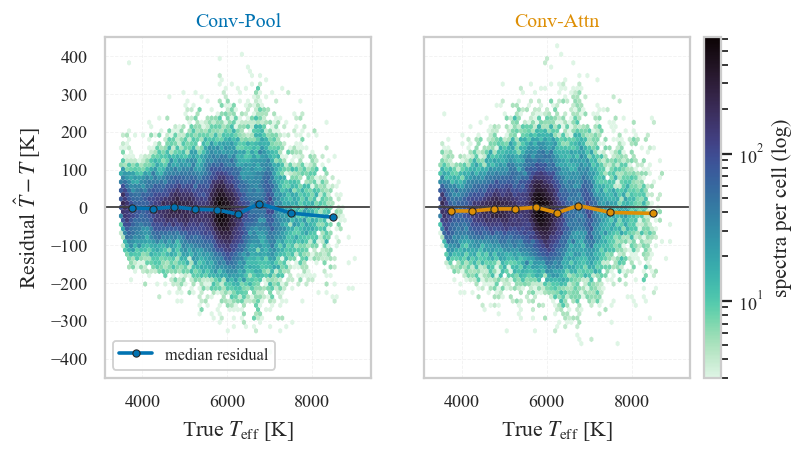

Pooled over 5 seeds: 94,490 points per panel; cells holding fewer than 3 spectra are left blank.
  Conv-Pool  99.88% of residuals lie inside +/-450 K
  Conv-Attn  99.90% of residuals lie inside +/-450 K


In [7]:
from matplotlib.colors import LogNorm

RES_CLIP = 450.0     # y-axis limit; the covered fraction is printed below
MINCNT   = 3         # blank the count-of-one halo, which exaggerates the spread

fig, axes = plt.subplots(1, len(MODELS), figsize=(W_DOUBLE, 3.4),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes)
extent = (y_true_k.min() - 100, y_true_k.max() + 100, -RES_CLIP, RES_CLIP)
bin_c = 0.5 * (np.array(REG_EDGES[:-1]) + np.array(REG_EDGES[1:]))
hbs, covered = [], []

for ax, m in zip(axes, MODELS):
    res = np.concatenate([clean_pred[(m, s)] - y_true_k for s in SEEDS])
    tru = np.tile(y_true_k, len(SEEDS))
    covered.append(float(np.mean(np.abs(res) <= RES_CLIP)))

    # one colormap for both panels: the colour bar is shared, and two different maps
    # would invite a density comparison the single bar cannot support
    hb = ax.hexbin(tru, res, gridsize=(60, 40), extent=extent, cmap='mako_r',
                   norm=LogNorm(), mincnt=MINCNT, linewidths=0)
    hbs.append(hb)

    ax.axhline(0, color='0.25', lw=1.0)
    reg = pd.cut(tru, bins=REG_EDGES)
    med = [np.median(res[np.asarray(reg == c)]) for c in reg.categories]
    ax.plot(bin_c, med, color=COLORS[m], lw=2.0, marker='o', ms=4,
            mec='0.15', mew=0.6, label='median residual', zorder=5)

    ax.set_xlabel(r'True $T_{\mathrm{eff}}$ [K]')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.25, lw=0.5)

vmax = max(h.get_array().max() for h in hbs)      # common density scale
for h in hbs:
    h.set_clim(MINCNT, vmax)

axes[0].set_ylabel(r'Residual $\hat{T} - T$ [K]')
axes[0].set_ylim(-RES_CLIP, RES_CLIP)
axes[0].legend(loc='lower left', framealpha=0.92, fontsize=9)
fig.colorbar(hbs[-1], ax=axes.tolist(), label='spectra per cell (log)', pad=0.02)
plt.show()

print(f'Pooled over {len(SEEDS)} seeds: {len(SEEDS) * N_TEST:,} points per panel; '
      f'cells holding fewer than {MINCNT} spectra are left blank.')
for m, f in zip(MODELS, covered):
    print(f'  {m:10s} {100 * f:.2f}% of residuals lie inside +/-{RES_CLIP:.0f} K')

## 5.0.6 Export

Two files. The metrics table holds the denominators; the metadata holds the constants the attack notebooks would otherwise each re-derive.

Clean per-spectrum predictions are not re-saved: Step 4 already wrote them to `testpreds_*.npz`, and the gate above has just confirmed that this notebook reproduces them.

In [8]:
clean_all = baseline[baseline['regime'] == 'all']
clean_summary = {}
for m in MODELS:
    sub = clean_all[clean_all['model'] == m]
    clean_summary[m] = {
        k: [float(sub[k].mean()), float(sub[k].std())]
        for k in ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']
    }

meta = {
    'step': '5.0',
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'teff_min': TEFF_MIN,
    'teff_range': TEFF_RANGE,
    'label_noise_floor_K': NOISE_FLOOR,
    'grid': GRID,
    'regime_edges_K': REG_EDGES,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'eval_batch_size': BATCH_SIZE,
    'clean': clean_summary,
    'gate_passed': True,
    'gate_max_abs_delta_K': worst,
}
with open(os.path.join(RESULTS_DIR, 'step50_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step50_')):
    print(f'  {fn:34s} {os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1024:7.1f} KB')
print(f'\nCheckpoints in {CKPT_DIR}/ are unchanged.')

Written to results/:
  step50_baseline_metrics.csv           14.3 KB
  step50_meta.json                       1.6 KB

Checkpoints in checkpoints/ are unchanged.


### Consumed by the attack notebooks

| File                          | Used for                                                                         |
|-------------------------------|----------------------------------------------------------------------------------|
| `step50_baseline_metrics.csv` | the per-model, per-seed, per-regime clean reference subtracted from every attack |
| `step50_meta.json`            | grid sampling, regime edges, gross-failure threshold, evaluation batch size      |

`load_model`, `predict` and `metrics` come from `common.py` in every attack notebook, so that a perturbed evaluation differs from the clean one in the input tensor and in nothing else.

Two instruments are deliberately deferred, since they serve the design of individual attacks rather than the baseline: the diagnostic line positions on the wavelength grid, and the occlusion-sensitivity scan that selects the masking target. Both belong to Step 5.2.